In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Dataset shape: (111, 60)
Columns: ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [12]:
if "Country" in df.columns:
    country_col = "Country"
elif "Entity" in df.columns:
    country_col = "Entity"
else:
    raise ValueError("Could not find a Country or Entity column.")

# Select India
country_name = "India"

if df[country_col].astype(str).str.strip().eq(country_name).any():
    country_df = df[
        df[country_col].astype(str).str.strip() == country_name
    ].copy()

elif "Year" not in df.columns:
    # Handle wide format: one column per year
    year_cols = [
        c for c in df.columns
        if str(c).isdigit()
    ]

    country_df = df[
        df[country_col].astype(str).str.strip() == country_name
    ].melt(
        id_vars=[country_col],
        value_vars=year_cols,
        var_name="Year",
        value_name="Consumption"
    )

else:
    raise ValueError(
        f"{country_name} not found. Available examples: "
        + ", ".join(df[country_col].dropna().astype(str).unique()[:20])
    )

# Handle wide-format data after selection
if "Year" not in country_df.columns:
    year_cols = [c for c in country_df.columns if str(c).isdigit()]
    country_df = country_df.melt(
        id_vars=[country_col],
        value_vars=year_cols,
        var_name="Year",
        value_name="Consumption"
    )

# If the dataset has a consumption column, use it
if "Consumption" not in country_df.columns:
    possible_cols = [
        c for c in country_df.columns
        if any(term in str(c).lower() for term in
               ["primary_energy_consumption", "energy_consumption"])
    ]

    if not possible_cols:
        raise ValueError(
            "Consumption column not found. Check the dataset column names."
        )

    country_df = country_df.rename(
        columns={possible_cols[0]: "Consumption"}
    )

country_df["Year"] = pd.to_numeric(country_df["Year"], errors="coerce")
country_df["Consumption"] = pd.to_numeric(
    country_df["Consumption"], errors="coerce"
)

country_df = country_df[["Year", "Consumption"]].dropna()
country_df = country_df[country_df["Consumption"] >= 0]
country_df = country_df.sort_values("Year")
country_df = country_df.drop_duplicates("Year", keep="last")

print("Selected country:", country_name)
print("Available records:", len(country_df))
print("Year range:", country_df["Year"].min(), "-", country_df["Year"].max())

display(country_df.head())

Selected country: India
Available records: 59
Year range: 1965 - 2023


,Year,Consumption
0,1965,2.23
1,1966,2.30
2,1967,2.37
3,1968,2.53
4,1969,2.81


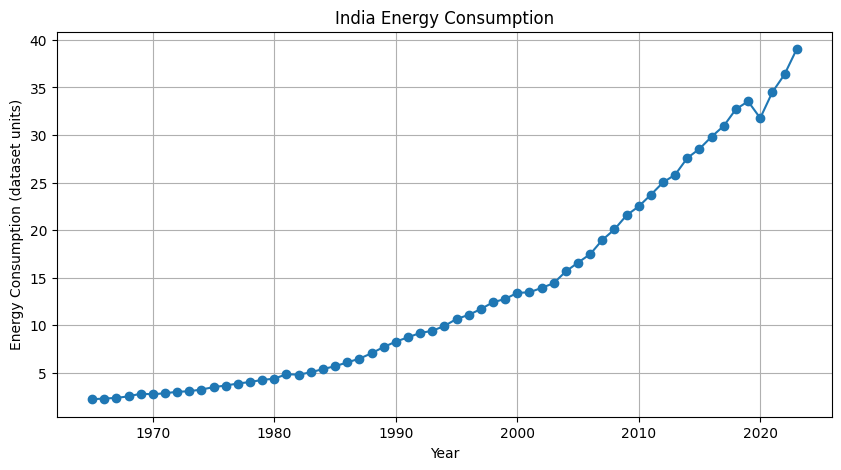

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(
    country_df["Year"],
    country_df["Consumption"],
    marker="o"
)
plt.title(f"{country_name} Energy Consumption")
plt.xlabel("Year")
plt.ylabel("Energy Consumption (dataset units)")
plt.grid(True)
plt.show()

In [14]:
values = country_df["Consumption"].values.reshape(-1, 1)
years = country_df["Year"].values

SEQUENCE_LENGTH = 5
split = int(len(values) * 0.8)

if split <= SEQUENCE_LENGTH or len(values) - split < 1:
    raise ValueError("Not enough yearly records to create train and test sets.")

scaler = MinMaxScaler()
scaler.fit(values[:split])

scaled_values = scaler.transform(values)

X, y, target_years = [], [], []

for i in range(SEQUENCE_LENGTH, len(scaled_values)):
    # Require consecutive years for each sequence
    if not np.all(np.diff(years[i-SEQUENCE_LENGTH:i+1]) == 1):
        continue

    X.append(scaled_values[i-SEQUENCE_LENGTH:i])
    y.append(scaled_values[i])
    target_years.append(years[i])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_years = np.array(target_years)

# The target year must fall within the chronological split
train_mask = target_years < years[split]
test_mask = target_years >= years[split]

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))
print("Input shape:", X_train.shape)

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Not enough consecutive records. Choose another country.")

Training sequences: 42
Testing sequences: 12
Input shape: (42, 5, 1)


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32, return_sequences=True,
         kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    LSTM(16, kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 5, 32)          │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,633 (29.82 KB)

 Trainable params: 7,633 (29.82 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    patience=7,
    factor=0.5,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=8,
    validation_data=(X_test, y_test),
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - loss: 0.2405 - val_loss: 1.9131 - learning_rate: 0.0010
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.2273 - val_loss: 1.8519 - learning_rate: 0.0010
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.2090 - val_loss: 1.7681 - learning_rate: 0.0010
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1789 - val_loss: 1.6036 - learning_rate: 0.0010
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1501 - val_loss: 1.3909 - learning_rate: 0.0010
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.1181 - val_loss: 1.1532 - learning_rate: 0.0010
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0973 - val_loss: 0.9153 - learning_rate: 0.0010
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0800 - val_loss: 0.6903 - learning_rate: 0.0010
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0725 - val_loss: 0.4950 - learning_rate: 0.0010
Epoch 10/200
6/6 ━━━━━━━━━━

In [24]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    patience=7,
    factor=0.5,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=8,
    validation_data=(X_test, y_test),
    shuffle=False,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0132 - val_loss: 0.0101 - learning_rate: 6.2500e-05
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0100 - val_loss: 0.0102 - learning_rate: 6.2500e-05
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0110 - val_loss: 0.0103 - learning_rate: 6.2500e-05
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0117 - val_loss: 0.0104 - learning_rate: 6.2500e-05
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0114 - val_loss: 0.0106 - learning_rate: 6.2500e-05
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0117 - val_loss: 0.0107 - learning_rate: 6.2500e-05
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0112 - val_loss: 0.0107 - learning_rate: 6.2500e-05
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0125 - val_loss: 0.0104 - learning_rate: 6.2500e-05
Epoch 9/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0097 - val_loss: 0.0102 - learning_rate: 3.1

In [25]:
pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler.inverse_transform(y_test)
y_predicted = scaler.inverse_transform(pred_scaled)

mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 0.6568
RMSE: 1.0654
